# NQ Overnight Range at the Cash Open

How do the overnight range in points, the opening location and pre-open volatility relate to which boundary NQ reaches? We start with the [reel’s two headline rates](https://www.instagram.com/reel/Dfai3hHvMDn/), then separate eventual touches, first-touch order and the intraday path.

One unadjusted, selected NQ contract per session. Times are New York local. Overnight is 18:00 to 09:30 and regular hours are 09:30 to 16:00, both excluding the end minute. Missing windows, equal-distance opens and unresolved minute order stay visible. Rates describe the retained sample. First-touch order is observed to one minute, and the notebook estimates neither fills nor profitability.

In [1]:
from datetime import date
import json
import os
from pathlib import Path
import sys
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from abacus_bhishma.paths import workspace_root

root = workspace_root()
study = root / "studies/32_nq_overnight_range"
source = Path(os.environ.get("ABACUS_NQ_SOURCE", study))
sys.path.insert(0, str(source))
from support import load_study, rates, save_figure, save_table, ridge_probabilities, block_interval

scratch = root / "work/32_nq_overnight_range"
scratch.mkdir(parents=True, exist_ok=True)
stage = Path(os.environ["ABACUS_NQ_STAGE"]) if "ABACUS_NQ_STAGE" in os.environ else Path(mkdtemp(dir=scratch))
for folder in ("tables", "figures"):
    (stage / folder).mkdir(exist_ok=True)
pin = json.loads((source / "inputs.lock.json").read_text())
settings = json.loads((source / "study.yaml").read_text())
facts, paths, overlap_checks = load_study(root, pin)
facts["year"] = facts.session_date.map(lambda day: day.year)
facts["era"] = np.where(facts.year < 2020, "2015–2019", "2020 onward")
facts["calendar_eligible"] = facts.calendar_status.eq("eligible")
facts["overnight_ready"] = facts.overnight_status.eq("complete")
facts["rth_ready"] = facts.rth_status.eq("complete")
facts["both_ready"] = facts.overnight_ready & facts.rth_ready
for field in ("overnight_high", "overnight_low", "overnight_width", "rth_open",
              "distance_to_high", "distance_to_low"):
    facts[field] = facts[field].astype(float)
facts["location"] = np.select(
    [~facts.overnight_ready, facts.rth_open.isna(), facts.overnight_width.eq(0),
     facts.distance_to_low.lt(0), facts.distance_to_low.eq(0), facts.distance_to_high.lt(0),
     facts.distance_to_high.eq(0), facts.distance_to_high.eq(facts.distance_to_low),
     facts.distance_to_high.lt(facts.distance_to_low)],
    ["overnight unavailable", "open unavailable", "degenerate", "below low", "at low",
     "above high", "at high", "midpoint", "upper half"], default="lower half")
facts["inside"] = facts.location.isin(["upper half", "lower half", "midpoint"])
facts["primary"] = facts.inside & facts.both_ready
facts["near_distance"] = facts[["distance_to_high", "distance_to_low"]].min(axis=1)
facts["far_distance"] = facts[["distance_to_high", "distance_to_low"]].max(axis=1)
modern_start = date.fromisoformat(settings["modern_start"])
holdout_start = date.fromisoformat(settings["holdout_start"])
facts["development"] = facts.session_date.ge(modern_start) & facts.session_date.lt(holdout_start)
facts["holdout"] = facts.session_date.ge(holdout_start)
pct = lambda value: f"{value:.1%}"
def note(message):
    display(Markdown(message))
def table(key, frame):
    save_table(stage, key, frame)
    display(frame.round(4))
def write_table(key, frame):
    save_table(stage, key, frame)
def plot(key, fig):
    save_figure(stage, key, fig)
def row_for(frame, group, metric):
    return frame.loc[frame.group.eq(group) & frame.metric.eq(metric)].iloc[0]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10, "axes.axisbelow": True,
                     "axes.grid": True, "grid.alpha": .18})

Matplotlib is building the font cache; this may take a moment.


## The overnight range

Start with the coverage, width and location of the cash open.

### Which NQ sessions can answer the question?

Inventory calendar eligibility, overnight and regular-hour completeness, and the final inside-range cohort. A valid open can exist even when a later RTH minute is missing.

In [2]:
coverage = facts.groupby("year", as_index=False).agg(
    roster=("asset", "size"), eligible=("calendar_eligible", "sum"),
    overnight_complete=("overnight_ready", "sum"), rth_complete=("rth_ready", "sum"),
    both_complete=("both_ready", "sum"), inside_primary=("primary", "sum"))
opening_counts = facts.loc[facts.both_ready].groupby(["era", "location"]).size().rename("n").reset_index()
facts[["session_date", "era", "calendar_status", "calendar_reasons", "overnight_status",
       "rth_status", "rth_open_status", "overnight_missing_minutes", "rth_missing_minutes",
       "location", "primary", "vxn_status", "vix_status"]].to_csv(stage / "tables/exclusions.csv", index=False)
write_table("opening-locations", opening_counts)

In [3]:
early = facts.year.le(2019)
late = facts.year.ge(2020)
note(f"The primary sample contains **{facts.primary.sum():,} inside-range sessions** "
     f"({facts.loc[early, 'primary'].sum():,} in 2015–2019 and "
     f"{facts.loc[late, 'primary'].sum():,} from 2020 onward). The strict early-era cohort "
     f"has {facts.loc[facts.year.le(2017), 'primary'].sum()} sessions from 2015–2017. "
     "The support by year matters when comparing eras.")

The primary sample contains **1,827 inside-range sessions** (307 in 2015–2019 and 1,520 from 2020 onward). The strict early-era cohort has 12 sessions from 2015–2017. The support by year matters when comparing eras.

In [4]:
table("coverage", coverage)

,year,roster,eligible,overnight_complete,rth_complete,both_complete,inside_primary
0,2015,261,250,1,250,1,1
1,2016,261,251,6,251,6,6
2,2017,260,249,5,249,5,5
3,2018,261,248,117,248,117,116
4,2019,261,249,179,249,179,179
5,2020,262,251,227,247,227,227
6,2021,261,251,225,251,225,225
7,2022,260,250,237,250,237,237
8,2023,260,248,217,248,217,216
9,2024,262,249,214,249,214,214


### How wide is the range, and where does NQ open?

Use complete overnight windows for width and available opening geometry for the location distribution. Points are NQ price points.

In [5]:
width_sample = facts.loc[facts.overnight_ready]
width_summary = width_sample.groupby("era").overnight_width.agg(
    n="count", median="median", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75)).reset_index()
inside_location = facts.loc[facts.inside]
write_table("width-by-era", width_summary)

In [6]:
outside = facts.loc[facts.both_ready, "location"].isin(["below low", "above high"]).sum()
boundary = facts.loc[facts.both_ready, "location"].isin(["at low", "at high"]).sum()
note(f"Median width was **{width_summary.iloc[0]['median']:.1f} NQ points** in 2015–2019 "
     f"and **{width_summary.iloc[1]['median']:.1f} points** from 2020 onward. "
     f"Of the two-window sessions, {outside} opened outside and {boundary} opened exactly at a boundary.")

Median width was **67.2 NQ points** in 2015–2019 and **160.2 points** from 2020 onward. Of the two-window sessions, 1 opened outside and 1 opened exactly at a boundary.

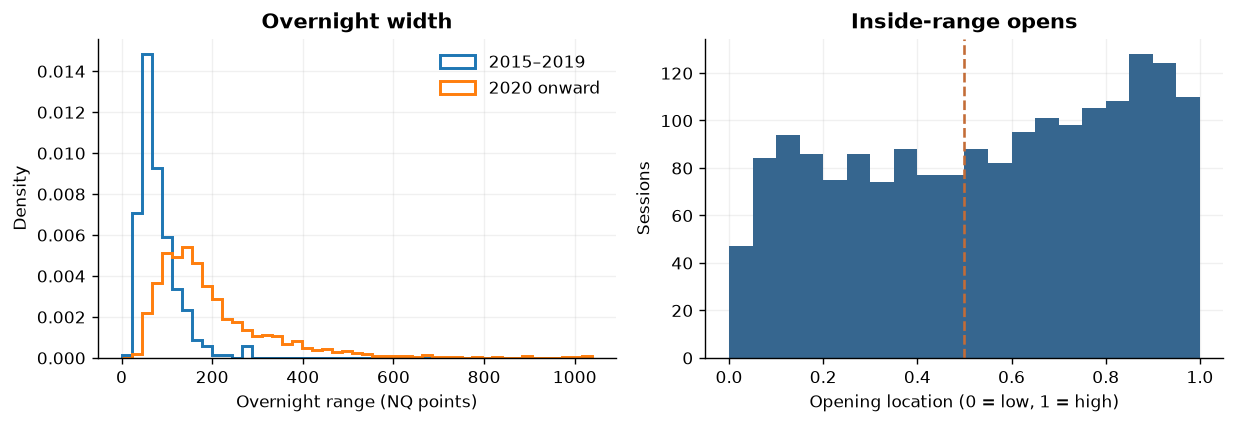

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for label, group in width_sample.groupby("era"):
    ax[0].hist(group.overnight_width, bins=np.linspace(0, width_sample.overnight_width.max(), 48),
               histtype="step", density=True, linewidth=1.7, label=label)
ax[0].set(xlabel="Overnight range (NQ points)", ylabel="Density", title="Overnight width")
ax[0].legend(frameon=False)
ax[1].hist(inside_location.normalized_open, bins=np.linspace(0, 1, 21), color="#36668f")
ax[1].axvline(.5, color="#c36c37", linestyle="--")
ax[1].set(xlabel="Opening location (0 = low, 1 = high)", ylabel="Sessions", title="Inside-range opens")
plot("opening-geometry", fig)

## Range size & volatility

Separate the observed overnight range from the broader volatility backdrop.

### How wide is the overnight range under low, middle and high volatility?

Compare pre-open VXN and VIX on identical dates. Fixed regime thresholds come from qualified modern development sessions through 2024.

In [8]:
matched_context = facts.overnight_ready & facts.vxn_close_preopen.notna() & facts.vix_close_preopen.notna()
development = facts.loc[matched_context & facts.development]
def cuts(series, unit):
    result = tuple(float(np.round(value / unit) * unit) for value in series.quantile([1/3, 2/3]))
    if result[0] >= result[1]:
        raise ValueError("regime thresholds must be distinct")
    return result
cutoffs = {
    "width": cuts(development.overnight_width, 10),
    "vxn": cuts(development.vxn_close_preopen, 1),
    "vix": cuts(development.vix_close_preopen, 1),
}
bands = {"width": ["Narrow", "Middle", "Wide"], "vol": ["Low", "Middle", "High"]}
facts["width_band"] = pd.cut(facts.overnight_width, [-np.inf, *cutoffs["width"], np.inf],
                             labels=bands["width"], right=False)
for symbol in ("vxn", "vix"):
    facts[symbol + "_band"] = pd.cut(facts[symbol + "_close_preopen"],
                                    [-np.inf, *cutoffs[symbol], np.inf], labels=bands["vol"], right=False)
facts["prior_width_median"] = np.nan
eligible_widths = facts.loc[facts.overnight_ready, "overnight_width"]
facts.loc[eligible_widths.index, "prior_width_median"] = eligible_widths.shift().rolling(
    settings["trailing_overnights"]).median()
facts["relative_width"] = facts.overnight_width / facts.prior_width_median.where(facts.prior_width_median.gt(0))
width_regimes = pd.concat([
    facts.loc[matched_context].groupby(symbol + "_band", observed=True)
    .overnight_width.agg(n="count", median="median", p25=lambda s: s.quantile(.25),
                         p75=lambda s: s.quantile(.75))
    .rename_axis("band").reset_index().assign(index_symbol=symbol.upper())
    for symbol in ("vxn", "vix")
], ignore_index=True)
(stage / "regime-cutoffs.json").write_text(json.dumps(cutoffs, indent=2) + chr(10))
write_table("width-by-volatility", width_regimes)

In [9]:
a = width_regimes.loc[width_regimes.index_symbol.eq("VXN")].set_index("band")
b = width_regimes.loc[width_regimes.index_symbol.eq("VIX")].set_index("band")
note(f"Median overnight width was **{a.loc['Low', 'median']:.1f} points in low VXN** and "
     f"**{a.loc['High', 'median']:.1f} in high VXN**. On the same {matched_context.sum():,} dates, "
     f"the corresponding VIX medians were {b.loc['Low', 'median']:.1f} and {b.loc['High', 'median']:.1f} points. "
     f"Frozen cutoffs are {cutoffs['width'][0]:.0f}/{cutoffs['width'][1]:.0f} NQ points, "
     f"{cutoffs['vxn'][0]:.0f}/{cutoffs['vxn'][1]:.0f} VXN and {cutoffs['vix'][0]:.0f}/{cutoffs['vix'][1]:.0f} VIX.")

Median overnight width was **105.0 points in low VXN** and **189.1 in high VXN**. On the same 1,829 dates, the corresponding VIX medians were 113.4 and 189.6 points. Frozen cutoffs are 120/170 NQ points, 21/29 VXN and 17/23 VIX.

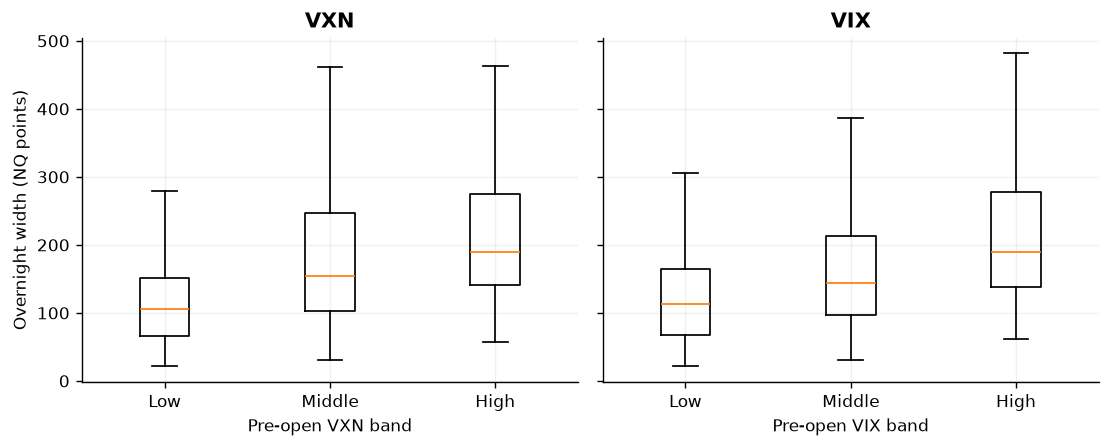

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.7), sharey=True)
for panel, symbol in zip(ax, ("vxn", "vix")):
    panel.boxplot([facts.loc[matched_context & facts[symbol + "_band"].eq(band), "overnight_width"]
                   for band in bands["vol"]], tick_labels=bands["vol"], showfliers=False)
    panel.set(xlabel="Pre-open " + symbol.upper() + " band", title=symbol.upper())
ax[0].set_ylabel("Overnight width (NQ points)")
plot("regime-width", fig)

### How much movement follows a narrow or wide overnight range?

Compare the median first-hour and regular-session range in NQ points. Relative width is the current width divided by the median of the preceding 60 complete eligible overnight windows.

In [11]:
day_motion = pd.DataFrame([
    {"session_date": day, "first60_range": path[:60, 1].max() - path[:60, 2].min(),
     "rth_range": path[:, 1].max() - path[:, 2].min()} for day, path in paths.items()])
motion = facts.loc[facts.both_ready].merge(day_motion, on="session_date", validate="one_to_one")
movement = motion.groupby(["width_band", "vxn_band"], observed=True).agg(
    n=("rth_range", "size"), first_hour_median=("first60_range", "median"),
    rth_median=("rth_range", "median")).reset_index()
relative_year = facts.groupby("year").agg(
    width_median=("overnight_width", "median"), relative_median=("relative_width", "median"),
    relative_n=("relative_width", "count")).reset_index()
write_table("relative-width-by-year", relative_year)
write_table("daytime-movement", movement)

In [12]:
small = movement.loc[movement.width_band.eq("Narrow") & movement.vxn_band.eq("High")].iloc[0]
large = movement.loc[movement.width_band.eq("Wide") & movement.vxn_band.eq("Low")].iloc[0]
note(f"Narrow/high-VXN sessions moved a median **{small.rth_median:.1f} points** during RTH "
     f"(n={small.n}). Wide/low-VXN sessions moved **{large.rth_median:.1f} points** (n={large.n}). "
     "Read small groups as descriptive. The width-relative-to-history line separates recent price scale "
     "from how unusual the overnight move was at the time.")

Narrow/high-VXN sessions moved a median **196.5 points** during RTH (n=66). Wide/low-VXN sessions moved **246.2 points** (n=123). Read small groups as descriptive. The width-relative-to-history line separates recent price scale from how unusual the overnight move was at the time.

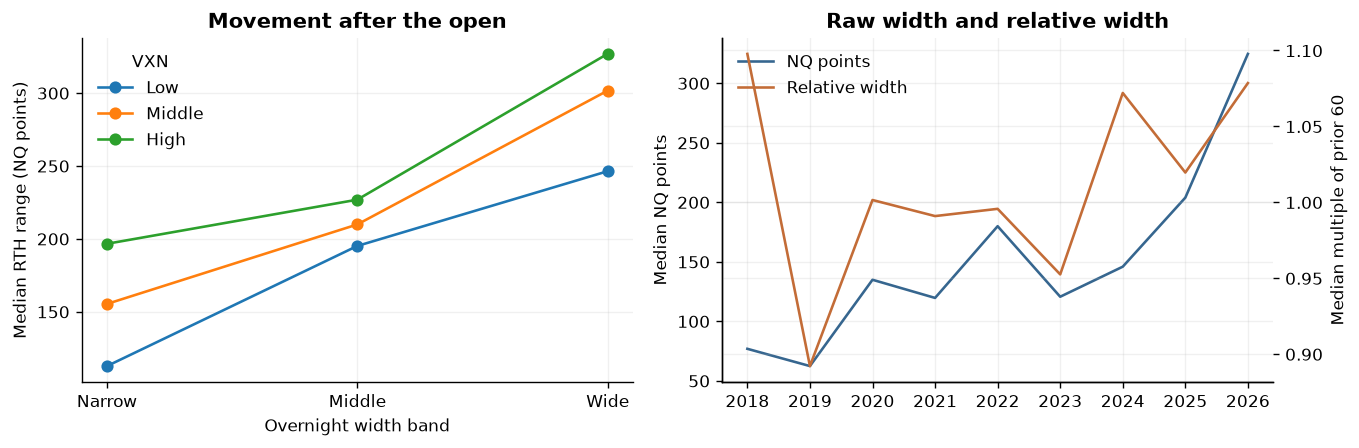

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for label, rows in movement.groupby("vxn_band", observed=True):
    adequate = rows.n.ge(settings["display_minimum"])
    ax[0].plot(rows.width_band.astype(str), rows.rth_median.where(adequate), marker="o", label=str(label))
ax[0].set(xlabel="Overnight width band", ylabel="Median RTH range (NQ points)", title="Movement after the open")
ax[0].legend(title="VXN", frameon=False)
second = ax[1].twinx()
adequate = facts.groupby("year").overnight_ready.sum().ge(settings["display_minimum"]).to_numpy()
line, = ax[1].plot(relative_year.year, relative_year.width_median.where(adequate), color="#36668f", label="NQ points")
ratio, = second.plot(relative_year.year,
                     relative_year.relative_median.where(relative_year.relative_n.ge(settings["display_minimum"])),
                     color="#c36c37", label="Relative width")
ax[1].set(title="Raw width and relative width", ylabel="Median NQ points")
second.set_ylabel("Median multiple of prior 60")
ax[1].legend(handles=[line, ratio], frameon=False)
plot("daytime-range", fig)

## Touch rates

Compare the reel’s conditional rates, then inspect how far and near outcomes vary with width and volatility.

### How often does NQ reach the overnight high or low?

A level is reached when a regular-hour minute trades at or beyond it. Each group contains sessions strictly inside the overnight range, with midpoint ties shown separately.

In [14]:
def threshold_times(path, high, low):
    upper = np.flatnonzero(path[:, 1] >= high)
    lower = np.flatnonzero(path[:, 2] <= low)
    return (int(upper[0]) if len(upper) else None, int(lower[0]) if len(lower) else None)

def first_side(upper, lower):
    if upper is None:
        return "neither" if lower is None else "low"
    if lower is None or upper < lower:
        return "high"
    return "same minute" if upper == lower else "low"

events = []
for row in facts.loc[facts.primary].itertuples():
    path = paths[row.session_date]
    upper, lower = threshold_times(path, row.overnight_high, row.overnight_low)
    upper_hit, lower_hit = upper is not None, lower is not None
    near_side = {"upper half": "high", "lower half": "low"}.get(row.location)
    order = first_side(upper, lower)
    has_near = near_side is not None
    near, far = (upper, lower) if near_side == "high" else (lower, upper)
    events.append({"session_date": row.session_date, "high_minute": upper, "low_minute": lower,
                   "hit_high": upper_hit, "hit_low": lower_hit, "both": upper_hit and lower_hit,
                   "neither": not (upper_hit or lower_hit), "order": order, "near_side": near_side,
                   "near_minute": near if has_near else None, "far_minute": far if has_near else None,
                   "near_hit": near is not None if has_near else None,
                   "far_hit": far is not None if has_near else None,
                   "near_first": order == near_side if has_near and order != "same minute" else None,
                   "far_first": order in ("high", "low") and order != near_side if has_near else None})
ledger = facts.loc[facts.primary].merge(pd.DataFrame(events), on="session_date", validate="one_to_one")
unique_near = ledger.loc[ledger.near_side.notna()].copy()
reel_rates = rates(ledger.groupby("location"), ["hit_high", "hit_low"])
reel_rates["reel"] = [0.808 if (row.group, row.metric) == ("upper half", "hit_high")
                      else 0.757 if (row.group, row.metric) == ("lower half", "hit_low")
                      else np.nan for row in reel_rates.itertuples()]
write_table("reel-touch-rates", reel_rates)
write_table("session-outcomes", ledger[[
    "session_date", "year", "era", "location", "overnight_width", "vxn_close_preopen", "vix_close_preopen",
    "distance_to_high", "distance_to_low", "hit_high", "hit_low", "both", "neither", "order",
    "near_side", "high_minute", "low_minute", "near_first", "far_first"]])

In [15]:
hi = row_for(reel_rates, "upper half", "hit_high")
lo = row_for(reel_rates, "lower half", "hit_low")
note(f"NQ reached the overnight high on **{pct(hi.rate)} of upper-half opens** ({hi.hits}/{hi.n}) "
     f"and the overnight low on **{pct(lo.rate)} of lower-half opens** ({lo.hits}/{lo.n}). "
     "The reel reported 80.8% and 75.7%, respectively. Its sample and exact event definitions are unknown.")

NQ reached the overnight high on **80.4% of upper-half opens** (830/1032) and the overnight low on **76.1% of lower-half opens** (600/788). The reel reported 80.8% and 75.7%, respectively. Its sample and exact event definitions are unknown.

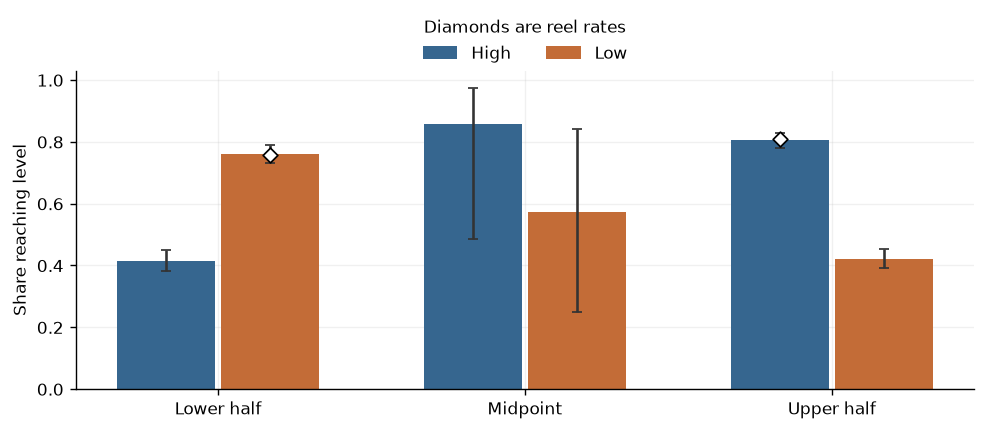

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for offset, metric, color in [(-.17, "hit_high", "#36668f"), (.17, "hit_low", "#c36c37")]:
    rows = reel_rates.loc[reel_rates.metric.eq(metric)].set_index("group").loc[
        ["lower half", "midpoint", "upper half"]]
    ax.bar(np.arange(3) + offset, rows.rate, .32, color=color, label=metric.replace("hit_", "").title())
    ax.errorbar(np.arange(3) + offset, rows.rate, yerr=[rows.rate - rows.low, rows.high - rows.rate],
                color="#333333", capsize=3, linestyle="none")
    for x, rate in zip(np.arange(3) + offset, rows.reel):
        if pd.notna(rate):
            ax.scatter(x, rate, marker="D", facecolor="white", edgecolor="black", zorder=4)
ax.set(xticks=range(3), xticklabels=["Lower half", "Midpoint", "Upper half"],
       ylabel="Share reaching level", ylim=(0, 1.03))
ax.legend(title="Diamonds are reel rates", frameon=False, loc="upper center",
          bbox_to_anchor=(.5, 1.21), ncol=2)
plot("reel-comparison", fig)

### Do narrow ranges make both sides easier to reach?

Show mutually exclusive near-only, far-only, both and neither outcomes by width. Equal-distance opens are separated from the near-versus-far view.

In [17]:
unique_near["touch_outcome"] = np.select(
    [unique_near.both, unique_near.neither, unique_near.near_hit.eq(True)],
    ["Both", "Neither", "Near only"], default="Far only")
touch_width = pd.crosstab(unique_near.width_band, unique_near.touch_outcome).reindex(bands["width"], fill_value=0)
write_table("touch-outcomes-by-width", touch_width.reset_index())

In [18]:
narrow, wide = touch_width.loc["Narrow"], touch_width.loc["Wide"]
note(f"Both boundaries were reached on **{pct(narrow.Both / narrow.sum())} of narrow sessions** "
     f"and **{pct(wide.Both / wide.sum())} of wide sessions**. The chart keeps both-side movement "
     "and directional-only movement separate.")

Both boundaries were reached on **32.6% of narrow sessions** and **17.4% of wide sessions**. The chart keeps both-side movement and directional-only movement separate.

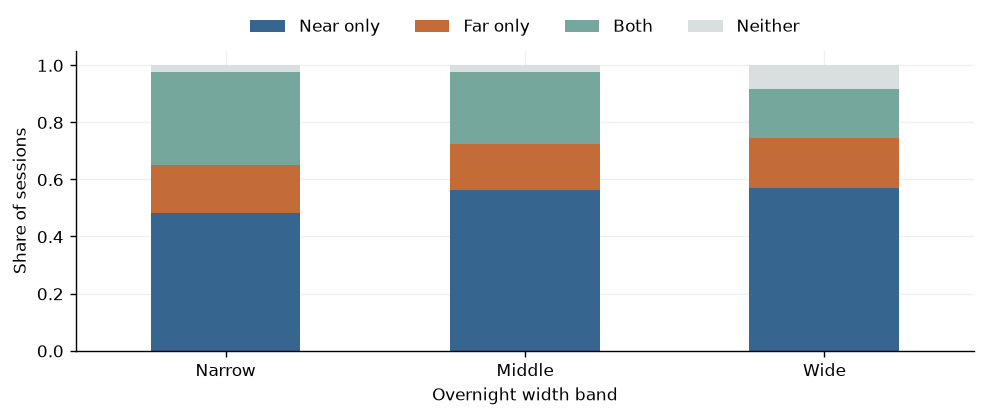

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.5))
touch_width.div(touch_width.sum(axis=1), axis=0)[["Near only", "Far only", "Both", "Neither"]].plot.bar(
    stacked=True, ax=ax, rot=0, color=["#36668f", "#c36c37", "#76a79c", "#d9dedf"])
ax.set(xlabel="Overnight width band", ylabel="Share of sessions")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(.5, 1.16))
plot("width-outcomes", fig)

### What happens when range width and volatility disagree?

Separate near-first from both-side reaches. Near-first chart rates keep same-minute cases in the full denominator as unresolved rather than awarding either side. Sparse cells show counts.

In [20]:
unique_near["near_first_confirmed"] = unique_near.near_first.eq(True)
unique_near["far_first_confirmed"] = unique_near.far_first.eq(True)
regime_groups = list(unique_near.groupby(["width_band", "vxn_band"], observed=True))
def matrix_rows(groups):
    return rates(groups, ["near_first_confirmed", "both"]).assign(
        width=lambda frame: frame.group.map(lambda key: key[0]),
        vxn=lambda frame: frame.group.map(lambda key: key[1]))
matrix = matrix_rows(regime_groups)
write_table("width-vxn-outcomes", matrix.drop(columns="group"))

In [21]:
focus = matrix.loc[(matrix.width.eq("Narrow") & matrix.vxn.eq("High")) |
                   (matrix.width.eq("Wide") & matrix.vxn.eq("Low"))]
def cell_summary(width, vxn):
    row = focus.loc[focus.width.eq(width) & focus.vxn.eq(vxn) & focus.metric.eq("both")].iloc[0]
    return f"{row.n} sessions" if row.n < settings["display_minimum"] else f"{pct(row.rate)} both-side reaches (n={row.n})"
note(f"Narrow/high VXN had **{cell_summary('Narrow', 'High')}**. "
     f"Wide/low VXN had **{cell_summary('Wide', 'Low')}**. The two panels distinguish "
     "which side was first from whether both sides were eventually reached.")

Narrow/high VXN had **42.4% both-side reaches (n=66)**. Wide/low VXN had **12.2% both-side reaches (n=123)**. The two panels distinguish which side was first from whether both sides were eventually reached.

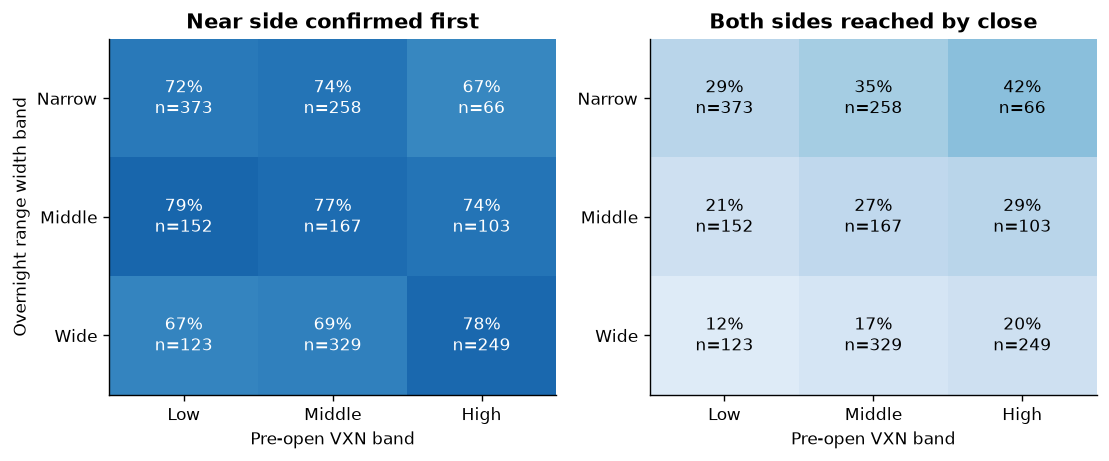

In [22]:
def matrix_panel(ax, frame, metric, title):
    subset = frame.loc[frame.metric.eq(metric)]
    counts = subset.pivot(index="width", columns="vxn", values="n").reindex(
        index=bands["width"], columns=bands["vol"]).fillna(0)
    estimates = subset.pivot(index="width", columns="vxn", values="rate").reindex_like(counts)
    image = ax.imshow(estimates.where(counts.ge(settings["display_minimum"])), vmin=0, vmax=1,
                      cmap="Blues", aspect="auto")
    for i, width in enumerate(counts.index):
        for j, regime in enumerate(counts.columns):
            n, value = int(counts.loc[width, regime]), estimates.loc[width, regime]
            text = f"{value:.0%}{chr(10)}n={n}" if n >= settings["display_minimum"] else f"n={n}"
            ax.text(j, i, text, ha="center", va="center", color="white" if n >= 25 and value > .65 else "black")
    ax.set(xticks=range(3), xticklabels=bands["vol"], yticks=range(3), yticklabels=bands["width"],
           xlabel="Pre-open VXN band", title=title)
    ax.grid(False)
    return image
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
matrix_panel(ax[0], matrix, "near_first_confirmed", "Near side confirmed first")
matrix_panel(ax[1], matrix, "both", "Both sides reached by close")
ax[0].set_ylabel("Overnight range width band")
plot("width-vxn", fig)

## First touch & path

Separate timing, first-touch order and the path before the near target.

### Which boundary goes first, and how fast?

Keep same-minute order unresolved. Timing curves use all unique-near eligible sessions, with misses remaining in the denominator through the full horizon.

In [23]:
unique_near["first_outcome"] = np.select(
    [unique_near.near_first_confirmed, unique_near.far_first_confirmed, unique_near.neither],
    ["Near first", "Far first", "Neither"], default="Unresolved")
first_counts = unique_near.first_outcome.value_counts().rename_axis("outcome").reset_index(name="n")
elapsed = np.arange(1, 391)
timing = pd.DataFrame({"minute": elapsed})
for key, field in [("Near", "near_minute"), ("Far", "far_minute")]:
    timing[key] = [unique_near[field].lt(minute).mean() for minute in elapsed]
write_table("first-touch-order", first_counts)
write_table("touch-timing", timing)

In [24]:
first_totals = first_counts.set_index("outcome").n
n = len(unique_near)
note(f"The near side went first on **{pct(first_totals['Near first'] / n)}** of sessions and "
     f"the far side on **{pct(first_totals['Far first'] / n)}**. "
     f"{first_totals.get('Unresolved', 0)} sessions had unresolved order. "
     f"By the first hour, the near side had been reached on {pct(timing.iloc[59].Near)} of all {n:,} sessions.")

The near side went first on **73.1%** of sessions and the far side on **22.3%**. 0 sessions had unresolved order. By the first hour, the near side had been reached on 65.7% of all 1,820 sessions.

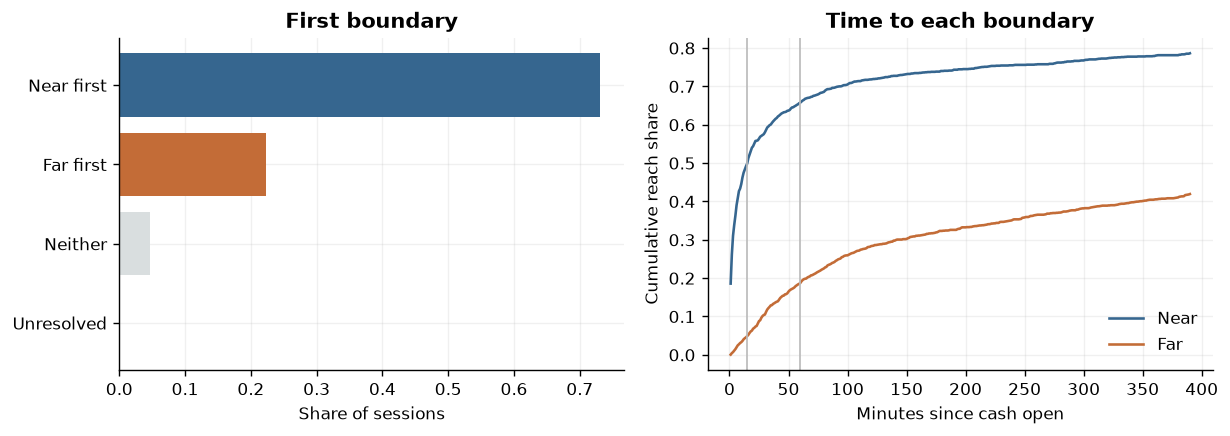

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
labels = ["Near first", "Far first", "Neither", "Unresolved"]
ax[0].barh(labels[::-1], [first_totals.get(label, 0) / len(unique_near) for label in labels[::-1]],
           color=["#c3c9cd", "#d9dedf", "#c36c37", "#36668f"])
ax[0].set(xlabel="Share of sessions", title="First boundary")
for side, color in [("Near", "#36668f"), ("Far", "#c36c37")]:
    ax[1].plot(timing.minute, timing[side], color=color, label=side)
for horizon in (15, 60):
    ax[1].axvline(horizon, color="#bbbbbb", linewidth=1)
ax[1].set(xlabel="Minutes since cash open", ylabel="Cumulative reach share", title="Time to each boundary")
ax[1].legend(frameon=False)
plot("first-timing", fig)

### How far does price move away from the near side?

Use the opening price as the reference. For hits, show a lower and upper bound because we cannot tell how much of the touch bar’s adverse extreme occurred before the touch.

In [26]:
def excursion_bounds(path, opening, side, target_minute):
    adverse = opening - path[:, 2] if side == "high" else path[:, 1] - opening
    if target_minute is None:
        excursion = max(0., float(adverse.max()))
        return excursion, excursion
    before = adverse[:target_minute]
    bar_open = path[target_minute, 0]
    gap = opening - bar_open if side == "high" else bar_open - opening
    lower = max(0., gap, float(before.max(initial=0)))
    return lower, max(lower, float(adverse[target_minute]))

adverse_rows = []
for row in unique_near.itertuples():
    minute = int(row.near_minute) if pd.notna(row.near_minute) else None
    low, high = excursion_bounds(paths[row.session_date], row.rth_open, row.near_side, minute)
    adverse_rows.append({"session_date": row.session_date, "near_reached": minute is not None,
                         "lower": low, "upper": high, "relative_lower": low / row.near_distance,
                         "relative_upper": high / row.near_distance})
adverse = pd.DataFrame(adverse_rows)
write_table("adverse-excursion", adverse)

In [27]:
hit = adverse.loc[adverse.near_reached]
miss = adverse.loc[~adverse.near_reached]
note(f"On near-side hits, median adverse excursion was bounded by **{hit.lower.median():.1f}–"
     f"{hit.upper.median():.1f} NQ points**. Sessions that missed the near side had a median "
     f"full-session adverse excursion of **{miss.lower.median():.1f} points** (n={len(miss):,}).")

On near-side hits, median adverse excursion was bounded by **14.5–16.5 NQ points**. Sessions that missed the near side had a median full-session adverse excursion of **182.0 points** (n=390).

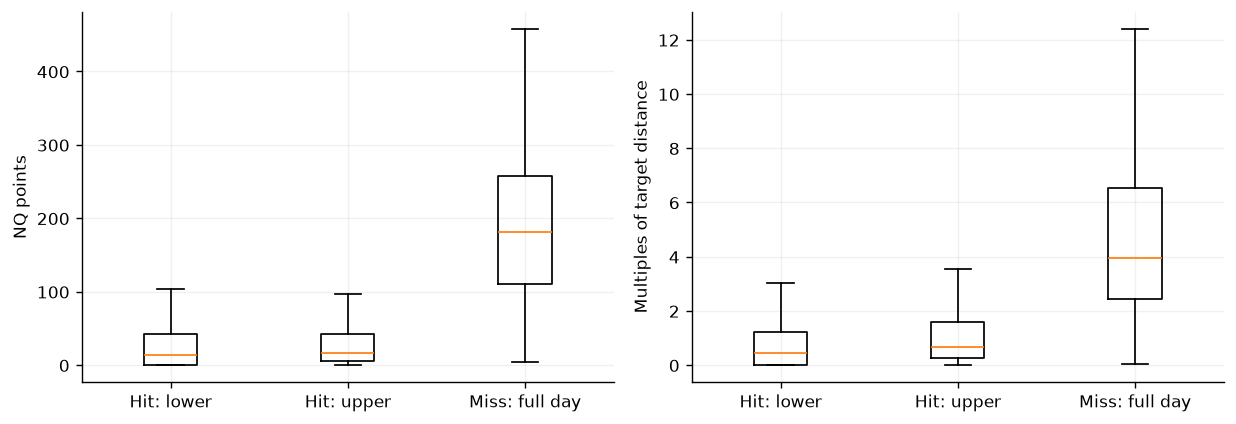

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for panel, (lo_key, hi_key, unit) in zip(ax, [
    ("lower", "upper", "NQ points"), ("relative_lower", "relative_upper", "Multiples of target distance")]):
    panel.boxplot([hit[lo_key], hit[hi_key], miss[lo_key]],
                  tick_labels=["Hit: lower", "Hit: upper", "Miss: full day"], showfliers=False)
    panel.set_ylabel(unit)
plot("excursion", fig)

### What remains after the opening minute?

Start the fresh-touch clock with the 09:31 minute. Remove sessions only when the specific boundary being measured was already reached in the opening minute.

In [29]:
fresh = []
for side in ("near", "far"):
    time = unique_near[side + "_minute"]
    pending = ~time.eq(0)
    hits = time.loc[pending].notna().sum()
    fresh.append({"target": side, "eligible_at_open": len(time), "opening_minute_touches": int((~pending).sum()),
                  "untouched_at_0931": int(pending.sum()), "fresh_hits": int(hits),
                  "fresh_rate": hits / pending.sum()})
fresh = pd.DataFrame(fresh)

In [30]:
near = fresh.iloc[0]
note(f"The nearer level was reached in the opening minute on **{near.opening_minute_touches:,} sessions**. "
     f"Of the {near.untouched_at_0931:,} still untouched at 09:31, **{pct(near.fresh_rate)}** reached it later.")

The nearer level was reached in the opening minute on **337 sessions**. Of the 1,483 still untouched at 09:31, **73.7%** reached it later.

In [31]:
table("fresh-touches", fresh)

,target,eligible_at_open,opening_minute_touches,untouched_at_0931,fresh_hits,fresh_rate
0,near,1820,337,1483,1093,0.7370
1,far,1820,0,1820,762,0.4187


## Beyond proximity

Compare distances with placebo paths and test whether volatility adds predictive information on later dates.

### Do actual boundaries outperform comparable paths at the same distances?

Replay both distances on prior regular-session paths, matched by opening side, VXN band and era. Use up to 20 dates within two calendar years and require at least five. Each study session receives equal weight.

In [32]:
placebo_rows = []
matches = unique_near.dropna(subset=["vxn_band"]).sort_values("session_date")
for (_, _, _), group in matches.groupby(["era", "near_side", "vxn_band"], observed=True):
    previous = []
    for row in group.itertuples():
        donors = [donor for donor in previous[-settings["placebo_donors"]:]
                  if (row.session_date - donor).days <= 730]
        if len(donors) >= settings["placebo_minimum"]:
            high_hits, low_hits, first_hits = [], [], []
            for donor in donors:
                path = paths[donor]
                origin = path[0, 0]
                upper, lower = threshold_times(path, origin + row.distance_to_high, origin - row.distance_to_low)
                high_hits.append(upper is not None)
                low_hits.append(lower is not None)
                first_hits.append(first_side(upper, lower) == row.near_side)
            placebo_rows.append({"session_date": row.session_date, "era": row.era, "donors": len(donors),
                                 "actual_near": row.near_hit,
                                 "actual_first": row.near_first_confirmed,
                                 "placebo_near": np.mean(high_hits if row.near_side == "high" else low_hits),
                                 "placebo_first": np.mean(first_hits)})
        previous.append(row.session_date)
placebo = pd.DataFrame(placebo_rows)
placebo_summary = placebo.groupby("era").agg(
    n=("donors", "size"), actual_near=("actual_near", "mean"), placebo_near=("placebo_near", "mean"),
    actual_first=("actual_first", "mean"), placebo_first=("placebo_first", "mean")).reset_index()
write_table("placebo-sessions", placebo)

In [33]:
modern_placebo = placebo_summary.loc[placebo_summary.era.eq("2020 onward")].iloc[0]
note(f"In the modern era, the near boundary was reached on **{pct(modern_placebo.actual_near)}** "
     f"of matched dates versus **{pct(modern_placebo.placebo_near)}** on donor paths at the same distances "
     f"(n={modern_placebo.n:,}). Prior-path matching can still leave differences in session conditions.")

In the modern era, the near boundary was reached on **78.6%** of matched dates versus **78.5%** on donor paths at the same distances (n=1,477). Prior-path matching can still leave differences in session conditions.

In [34]:
table("placebo-comparison", placebo_summary)

,era,n,actual_near,placebo_near,actual_first,placebo_first
0,2015–2019,271,0.7749,0.7846,0.7159,0.7261
1,2020 onward,1477,0.7861,0.7849,0.7312,0.7268


### At similar distances, what changes in high VXN?

Compare high and low VXN in the modern era. Use the same near-target distance distribution for both groups. Weight only distance bands with at least 25 sessions in each group. This exploratory comparison adjusts for near distance. The held-out models also account for far distance.

In [35]:
modern = unique_near.loc[unique_near.development | unique_near.holdout].copy()
modern["distance_band"] = pd.cut(modern.near_distance, [0, 25, 50, 100, np.inf], right=False)
vol_groups = modern.loc[modern.vxn_band.isin(["Low", "High"])]
distance_metrics = ["near_first_confirmed", "both"]
distance_rows = rates(vol_groups.groupby(["distance_band", "vxn_band"], observed=True), distance_metrics)
distance_rows["distance"] = distance_rows.group.map(lambda key: key[0])
distance_rows["vxn"] = distance_rows.group.map(lambda key: key[1])
support = distance_rows.loc[distance_rows.metric.eq("both")].pivot(index="distance", columns="vxn", values="n")
common = support.loc[support[["Low", "High"]].ge(settings["display_minimum"]).all(axis=1)]
weights = common.sum(axis=1) / common.to_numpy().sum()
weighted_rows = []
for metric in distance_metrics:
    estimates = distance_rows.loc[distance_rows.metric.eq(metric)].pivot(index="distance", columns="vxn", values="rate")
    standardized = estimates.loc[common.index, ["Low", "High"]].mul(weights, axis=0).sum()
    weighted_rows.append({"outcome": metric, "low_vxn": standardized["Low"], "high_vxn": standardized["High"],
                          "high_minus_low": standardized["High"] - standardized["Low"],
                          "low_n": int(common.Low.sum()), "high_n": int(common.High.sum())})
weighted = pd.DataFrame(weighted_rows)
distance_rows["common_weight"] = distance_rows.distance.map(weights.to_dict())
write_table("distance-matched-vxn-strata", distance_rows.drop(columns="group"))

In [36]:
first, both = weighted.iloc[0], weighted.iloc[1]
note(f"With the same near-distance mix, confirmed near-first was **{pct(first.low_vxn)} in low VXN** "
     f"and **{pct(first.high_vxn)} in high VXN**. Both-side reaches were **{pct(both.low_vxn)}** "
     f"and **{pct(both.high_vxn)}**. This covers {len(common)} shared distance bands "
     f"({first.low_n} low-VXN sessions and {first.high_n} high-VXN sessions).")

With the same near-distance mix, confirmed near-first was **73.1% in low VXN** and **79.0% in high VXN**. Both-side reaches were **24.8%** and **26.8%**. This covers 3 shared distance bands (465 low-VXN sessions and 354 high-VXN sessions).

In [37]:
table("distance-matched-vxn", weighted)

,outcome,low_vxn,high_vxn,high_minus_low,low_n,high_n
0,near_first_confirmed,0.7314,0.7895,0.0581,465,354
1,both,0.2477,0.2681,0.0205,465,354


### Does VXN or VIX improve probability estimates on later dates?

Compare distance-only and volatility-augmented models on identical dates from 2025 onward. Lower Brier loss is better. For near-first, omit unresolved ordering; neither remains a negative.

In [38]:
models = {"Distances": [], "Distances + VXN": ["vxn_close_preopen"], "Distances + VIX": ["vix_close_preopen"]}
model_rows, predictions, calibration = [], [], []
for outcome in ("near_first", "both"):
    sample = unique_near.dropna(subset=[outcome, "vxn_close_preopen", "vix_close_preopen"]).sort_values("session_date")
    train, test = sample.loc[sample.development], sample.loc[sample.holdout]
    train_y, test_y = train[outcome].astype(float).to_numpy(), test[outcome].astype(float).to_numpy()
    errors = {}
    for name, features in models.items():
        predictors = ["near_distance", "far_distance", *features]
        x, future = train[predictors].to_numpy(), test[predictors].to_numpy()
        x[:, :2], future[:, :2] = np.log1p(x[:, :2]), np.log1p(future[:, :2])
        prediction = ridge_probabilities(x, train_y, future)
        errors[name] = (prediction - test_y) ** 2
        diff = errors[name] - errors["Distances"]
        low, high = block_interval(diff, settings["bootstrap_seed"])
        model_rows.append({"outcome": outcome, "model": name, "training_n": len(train), "holdout_n": len(test),
                           "brier": errors[name].mean(), "delta": diff.mean(),
                           "delta_low": low, "delta_high": high, "mean_predicted": prediction.mean(),
                           "observed_rate": test_y.mean()})
        for day, observed, estimate in zip(test.session_date, test_y, prediction):
            predictions.append({"outcome": outcome, "model": name, "session_date": day,
                                "observed": observed, "prediction": estimate})
        for band, p in pd.DataFrame({"estimate": prediction, "observed": test_y}).groupby(
                pd.cut(prediction, np.linspace(0, 1, 6), include_lowest=True), observed=True):
            calibration.append({"outcome": outcome, "model": name, "band": str(band), "n": len(p),
                                "mean_predicted": p.estimate.mean(), "observed_rate": p.observed.mean()})
model_scores = pd.DataFrame(model_rows)
write_table("holdout-predictions", pd.DataFrame(predictions))
write_table("holdout-calibration", pd.DataFrame(calibration))

In [39]:
supported = model_scores.loc[model_scores.delta_high.lt(0)]
if len(supported):
    text = ", ".join(f"{row.model} for {row.outcome.replace('_', ' ')}" for row in supported.itertuples())
    note(f"The paired intervals support lower held-out Brier loss for **{text}**. "
         "A negative change favors the index model. These outcomes measure price behavior.")
else:
    note("**Neither volatility index showed a clear improvement in held-out Brier loss.** "
         "The paired intervals for the index models include zero or are above zero. "
         "The conclusion applies to these fixed models and the available later-period sample.")

**Neither volatility index showed a clear improvement in held-out Brier loss.** The paired intervals for the index models include zero or are above zero. The conclusion applies to these fixed models and the available later-period sample.

In [40]:
table("holdout-model-scores", model_scores)

,outcome,model,training_n,holdout_n,brier,delta,delta_low,delta_high,mean_predicted,observed_rate
0,near_first,Distances,1114,400,0.1876,0.0000,0.0000,0.0000,0.6949,0.7050
1,near_first,Distances + VXN,1114,400,0.1885,0.0009,-0.0033,0.0056,0.6559,0.7050
2,near_first,Distances + VIX,1114,400,0.1867,-0.0009,-0.0042,0.0027,0.6657,0.7050
3,both,Distances,1114,400,0.1587,0.0000,0.0000,0.0000,0.1759,0.2125
4,both,Distances + VXN,1114,400,0.1610,0.0024,-0.0000,0.0048,0.1484,0.2125
5,both,Distances + VIX,1114,400,0.1606,0.0020,-0.0001,0.0042,0.1528,0.2125


## Era & yearly stability

Compare the pooled eras with recent year-by-year results and a common September cutoff.

### Did the results survive a change in era or year?

Compare 2015–2019, 2018–2019 as a coverage sensitivity, and 2020 onward. The recent annual panel covers 2023–2026. The common-cutoff table uses only January through September 18 each year.

In [41]:
annual_years = settings["annual_years"]
month, day = settings["annual_cutoff_month_day"]
group_sets = [
    ("2015–2019", unique_near.loc[unique_near.year.le(2019)]),
    ("2018–2019", unique_near.loc[unique_near.year.between(2018, 2019)]),
    ("2020 onward", unique_near.loc[unique_near.year.ge(2020)]),
    *[(str(year), unique_near.loc[unique_near.year.eq(year)]) for year in annual_years],
]
stability_metrics = ["near_hit", "far_hit", "near_first_confirmed", "far_first_confirmed", "both", "neither"]
era_rates = rates(group_sets, stability_metrics)
common_cutoff = unique_near.session_date.map(lambda date: (date.month, date.day) <= (month, day))
year_rates_cutoff = rates([(str(year), unique_near.loc[common_cutoff & unique_near.year.eq(year)])
                          for year in annual_years], stability_metrics)
half_stability = pd.concat([rates(g.groupby("location"), ["hit_high", "hit_low"]).assign(period=label)
                            for label, g in group_sets], ignore_index=True)
width_period = pd.DataFrame([{"period": label, "n": len(g),
                              "median_points": g.overnight_width.median(),
                              "median_relative": g.relative_width.median()}
                             for label, g in group_sets])
for key, frame in [("era-year-rates", era_rates), ("annual-common-cutoff", year_rates_cutoff),
                   ("half-touch-stability", half_stability), ("era-year-width", width_period)]:
    write_table(key, frame)

In [42]:
a, b = [row_for(era_rates, group, "near_first_confirmed") for group in ("2015–2019", "2020 onward")]
old_support = facts.loc[facts.year.between(2018, 2019), "primary"].sum()
old_total = facts.loc[facts.year.le(2019), "primary"].sum()
note(f"The near side went first on **{pct(a.rate)}** in 2015–2019 (n={a.n:,}) and "
     f"**{pct(b.rate)}** from 2020 onward (n={b.n:,}). "
     f"2018–2019 contributed {old_support}/{old_total} of the earlier inside-range sessions. "
     "2026 ends September 18. The saved common-cutoff table applies that date to every recent year.")

The near side went first on **72.2%** in 2015–2019 (n=306) and **73.3%** from 2020 onward (n=1,514). 2018–2019 contributed 295/307 of the earlier inside-range sessions. 2026 ends September 18. The saved common-cutoff table applies that date to every recent year.

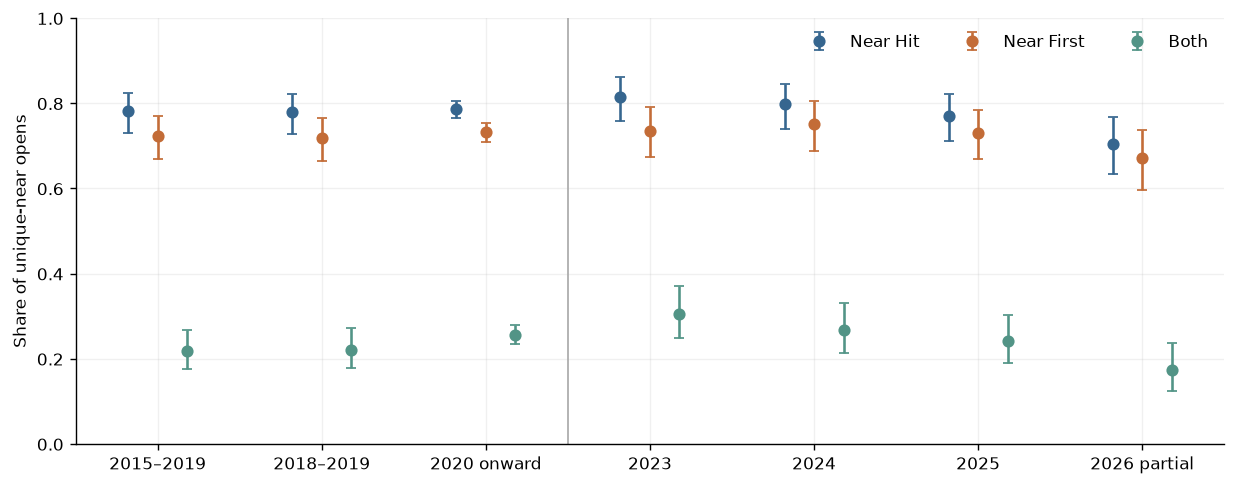

In [43]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = [label for label, _ in group_sets]
for offset, metric, color in [(-.18, "near_hit", "#36668f"), (0, "near_first_confirmed", "#c36c37"),
                              (.18, "both", "#529486")]:
    subset = era_rates.loc[era_rates.metric.eq(metric)].set_index("group").loc[labels]
    ax.errorbar(np.arange(len(labels)) + offset, subset.rate,
                yerr=[subset.rate - subset.low, subset.high - subset.rate], marker="o", linestyle="none",
                capsize=3, color=color, label=metric.replace("_confirmed", "").replace("_", " ").title())
ax.axvline(2.5, color="#aaaaaa", linewidth=1)
ax.set(xticks=range(len(labels)), xticklabels=[*labels[:-1], "2026 partial"],
       ylabel="Share of unique-near opens", ylim=(0, 1))
ax.legend(frameon=False, ncol=3)
plot("annual-stability", fig)

### How did overnight width and pre-open volatility change across recent years?

Compare the annual median range, the median relative to the prior 60 eligible windows, and the pre-open volatility backdrop. The year-to-date columns use the same September 18 cutoff for each year.

In [44]:
recent_width = facts.loc[facts.year.isin(annual_years) & facts.overnight_ready].copy()
recent_width["through_cutoff"] = recent_width.session_date.map(lambda value: (value.month, value.day) <= (month, day))
width_annual = recent_width.groupby("year").agg(
    n=("overnight_width", "size"), median_points=("overnight_width", "median"),
    p25_points=("overnight_width", lambda values: values.quantile(.25)),
    p75_points=("overnight_width", lambda values: values.quantile(.75)),
    relative_n=("relative_width", "count"), relative_median=("relative_width", "median"),
    vxn_median=("vxn_close_preopen", "median"), vix_median=("vix_close_preopen", "median"))
cutoff_width = recent_width.loc[recent_width.through_cutoff].groupby("year").overnight_width.agg(
    cutoff_n="size", cutoff_median_points="median")
width_annual = width_annual.join(cutoff_width).reset_index()

In [45]:
first, last = width_annual.iloc[0], width_annual.iloc[-1]
note(f"Through September 18 in each year, median overnight width was **{first.cutoff_median_points:.1f} points "
     f"in {int(first.year)}** and **{last.cutoff_median_points:.1f} points in {int(last.year)}**. "
     "The trailing-width ratio and volatility medians help put the raw point change in context.")

Through September 18 in each year, median overnight width was **124.8 points in 2023** and **324.5 points in 2026**. The trailing-width ratio and volatility medians help put the raw point change in context.

In [46]:
table("annual-width-and-volatility", width_annual)

,year,n,median_points,p25_points,p75_points,relative_n,relative_median,vxn_median,vix_median,cutoff_n,cutoff_median_points
0,2023,217,120.50,85.000,160.7500,217,0.9525,21.360,17.020,149,124.75
1,2024,214,145.75,116.625,192.9375,214,1.0719,18.540,14.665,150,144.50
2,2025,228,203.75,143.750,306.0000,228,1.0195,20.725,17.290,161,206.00
3,2026,173,324.50,233.000,431.2500,173,1.0785,23.950,17.430,173,324.50


### Do width and VXN tell the same story in each era?

Use the same fixed point and VXN bands in both eras. These cells contain different mixes of opening distances, so compare them with the held-out distance-adjusted analysis.

In [47]:
era_matrices = {label: matrix_rows(group.groupby(["width_band", "vxn_band"], observed=True))
                for label, group in unique_near.groupby("era")}
write_table("era-width-vxn", pd.concat([
    frame.drop(columns="group").assign(era=label) for label, frame in era_matrices.items()], ignore_index=True))
distance_edges = [-np.inf, 25, 50, 100, np.inf]
unique_near["distance_band"] = pd.cut(unique_near.near_distance, distance_edges, right=False)
matched_distances = rates(unique_near.groupby(["distance_band", "vxn_band"], observed=True),
                          ["near_first_confirmed", "both"])
write_table("distance-vxn-outcomes", matched_distances)
focus = unique_near.loc[((unique_near.width_band.eq("Narrow") & unique_near.vxn_band.eq("High")) |
                        (unique_near.width_band.eq("Wide") & unique_near.vxn_band.eq("Low")))].copy()
focus["opening_band"] = pd.cut(focus.near_distance / focus.overnight_width,
                              [0, .125, .25, .375, .5], include_lowest=True)
focus["scenario"] = np.where(focus.width_band.eq("Narrow"), "Narrow/high VXN", "Wide/low VXN")
write_table("width-vxn-scenarios-by-opening", rates(
    focus.groupby(["scenario", "opening_band"], observed=True), ["near_first_confirmed", "both"]))

In [48]:
early_supported = era_matrices["2015–2019"].query("metric == 'both'").n.ge(settings["display_minimum"]).sum()
late_supported = era_matrices["2020 onward"].query("metric == 'both'").n.ge(settings["display_minimum"]).sum()
note(f"**{early_supported} of 9 cells** in the earlier era and **{late_supported} of 9** in the modern era "
     "have at least 25 sessions. Rates in cells below that threshold are visually muted to counts. "
     "The saved distance table groups by near-target distance, and the scenario table groups by relative opening location.")

**2 of 9 cells** in the earlier era and **9 of 9** in the modern era have at least 25 sessions. Rates in cells below that threshold are visually muted to counts. The saved distance table groups by near-target distance, and the scenario table groups by relative opening location.

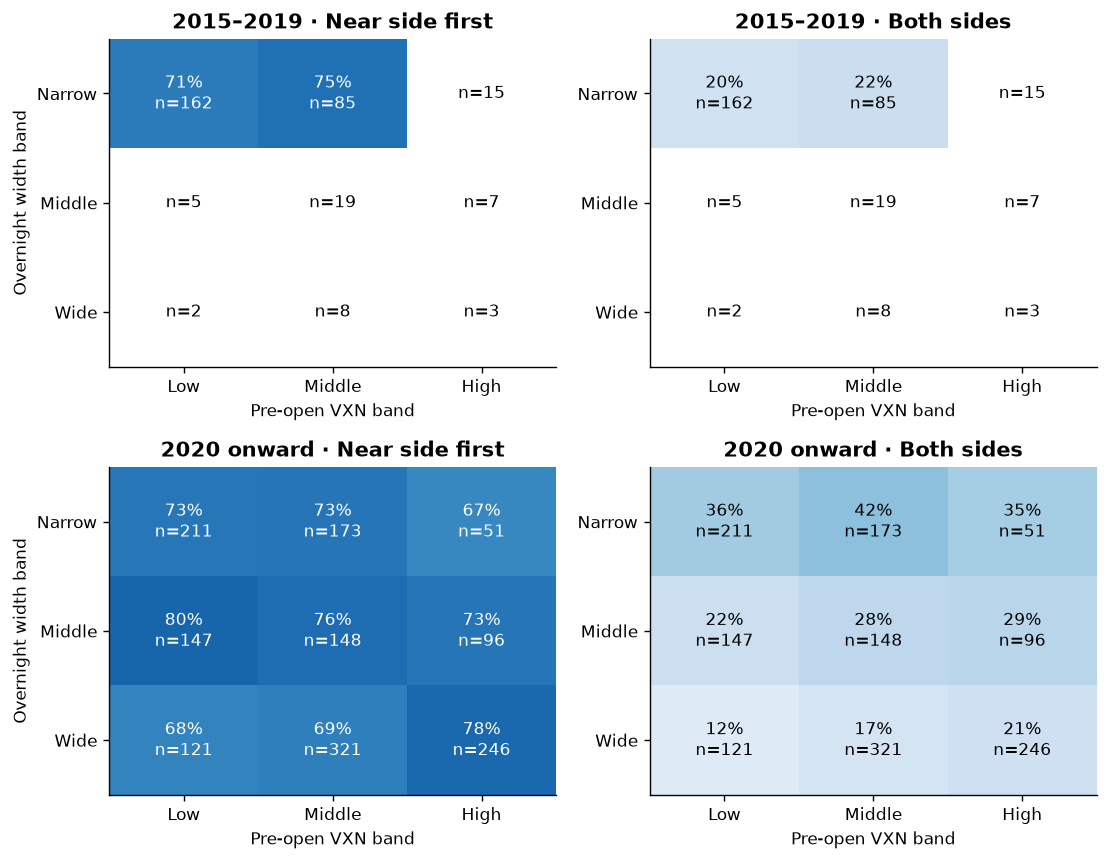

In [49]:
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
for panels, (label, frame) in zip(ax, era_matrices.items()):
    matrix_panel(panels[0], frame, "near_first_confirmed", label + " · Near side first")
    matrix_panel(panels[1], frame, "both", label + " · Both sides")
    panels[0].set_ylabel("Overnight width band")
plot("era-regimes", fig)

In [50]:
assert len(ledger) == int(facts.primary.sum())
assert not ledger.session_date.duplicated().any()
assert (ledger.both == (ledger.hit_high & ledger.hit_low)).all()
assert (ledger.neither == ~(ledger.hit_high | ledger.hit_low)).all()
assert len(unique_near) + ledger.location.eq("midpoint").sum() == len(ledger)
assert int(first_counts.n.sum()) == len(unique_near)
assert set(era_matrices) == {"2015–2019", "2020 onward"}
(stage / "notebook-checks.json").write_text(json.dumps({
    "roster": len(facts), "primary": len(ledger), "unique_near": len(unique_near),
    "daily_facts_rth_extrema_checks": overlap_checks, "themes": 6,
}, indent=2) + chr(10))

120